# Spectroscopy
This notebook is for getting the wavelengths of bands from an input spectrum image.

In [2]:
# imports
import matplotlib.pyplot as plt
import os
import glob
import numpy as np

import cv2

import tifffile

from scipy.signal import find_peaks
from scipy.ndimage import gaussian_filter1d

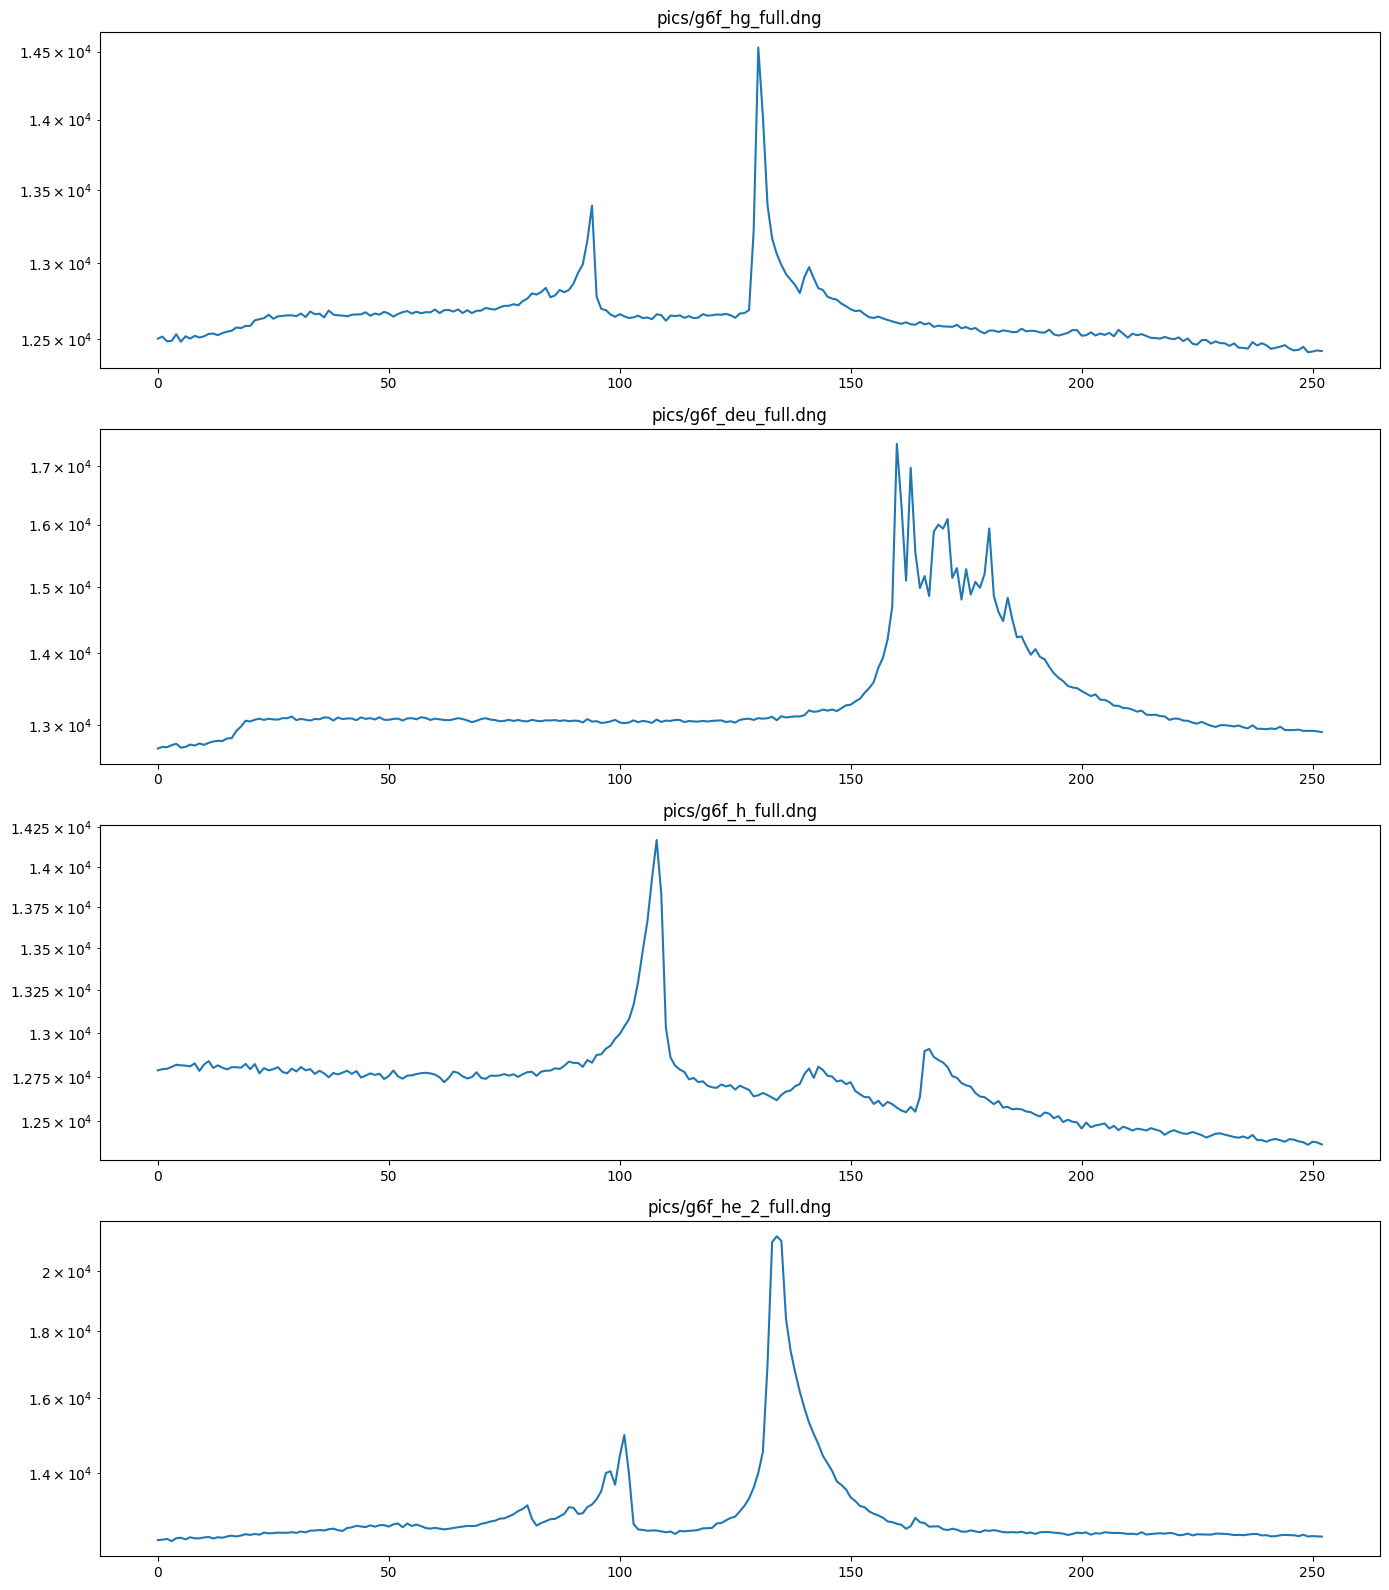

In [3]:
# isolating bands from background
# first do a quick vertical sum to see

picFiles_list = glob.glob(os.path.join("*pics","*"))
counter = 1
total = len(picFiles_list)

fig, axes = plt.subplots(int(total), 1, figsize = (14, 4 * total))

#print(picFiles_list)
for ax, pic in zip(axes.flat, picFiles_list):
    img = cv2.imread(pic)
    h, w, _ = img.shape
    vert_sum = list(map(lambda x: x[0], np.sum(img, axis = 0)))
    #print(vert_sum)
    # print(np.sum((img), axis = 0))
    # print(len(np.sum((img), axis = 0)))

    ax.plot(range(len(vert_sum)), vert_sum)
    ax.set_yscale("log")
    ax.set_title(pic)
    counter += 1

fig.tight_layout()

In [4]:
# we've lost a lot of the faint bands from summing background
# let's fix this by only summing the relavant bands
# also the compression ot preview is doing nasty stuff (WHY is that default????)
# make func to get proper pics and get bands

def get_full_pic(pic):
    with tifffile.TiffFile(pic) as tif:
        img = tif.series[1].asarray()
    return img

def get_band(pic, band_prop = 5):
    #print(f"Image: {pic}")
    img = get_full_pic(pic)
    h, w = img.shape
    #print(img.shape) #(3040, 4056)

    # get brightest 1/5 of image rows next to each other
    row_total_brightness = np.sum(img, axis = 1)
    #print(len(row_total_brightness)) 3040, correct

    band_size = int(h / 5)
    y_0 = 0
    brightest = 0

    for i in range(h):
        # flatten list then sum
        brightness_sum = sum(row_total_brightness[i:i+band_size])
        if brightness_sum > brightest:
            y_0 = i
            brightest = brightness_sum
        #print(brightness_sum)

    return y_0, y_0 + band_size

[(927, 1535), (869, 1477), (931, 1539), (855, 1463)]


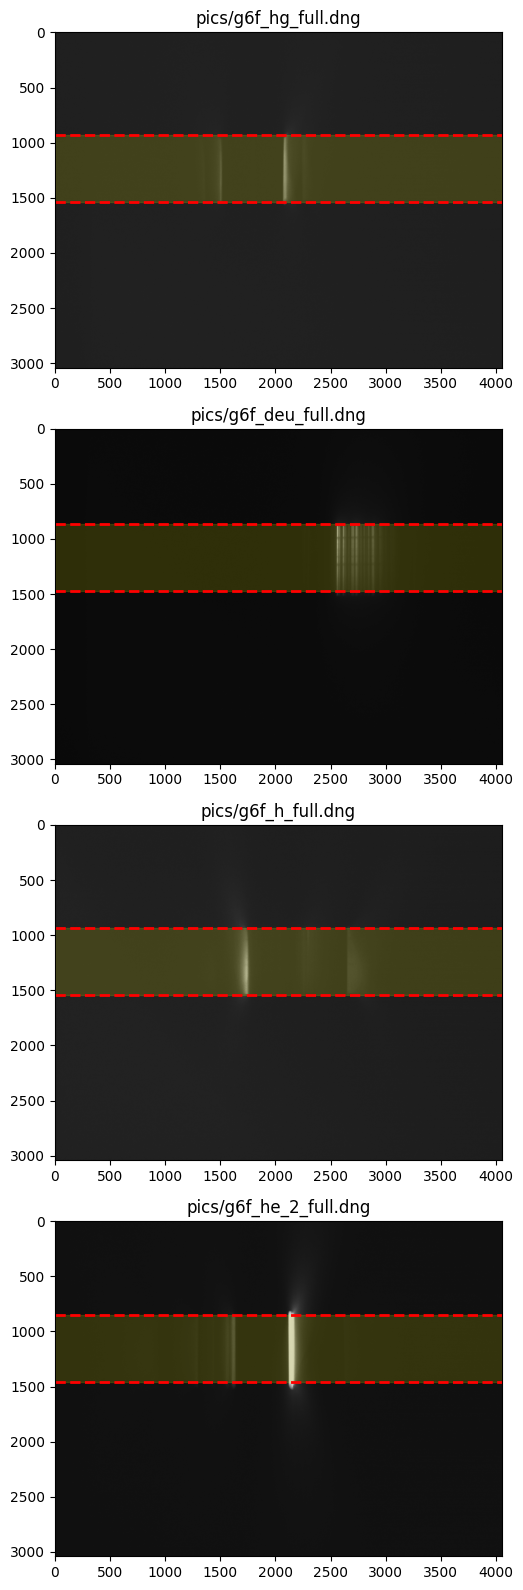

In [5]:
# let's check the bands

regions = []
for pic in picFiles_list:
    regions.append(get_band(pic))

print(regions)

fig, axes = plt.subplots(int(total), 1, figsize = (14, 4 * total))

for ax, pic, (y0, y1) in zip(axes.flat, picFiles_list, regions):

    img = get_full_pic(pic)

    ax.imshow(img, cmap="gray")

    # Draw upper and lower boundaries
    ax.axhline(y0, color="red", linestyle="--", linewidth=2)
    ax.axhline(y1, color="red", linestyle="--", linewidth=2)

    # Optional: shade the selected region
    ax.axhspan(y0, y1, color="yellow", alpha=0.15)

    ax.set_title(pic)

plt.tight_layout()
plt.show()

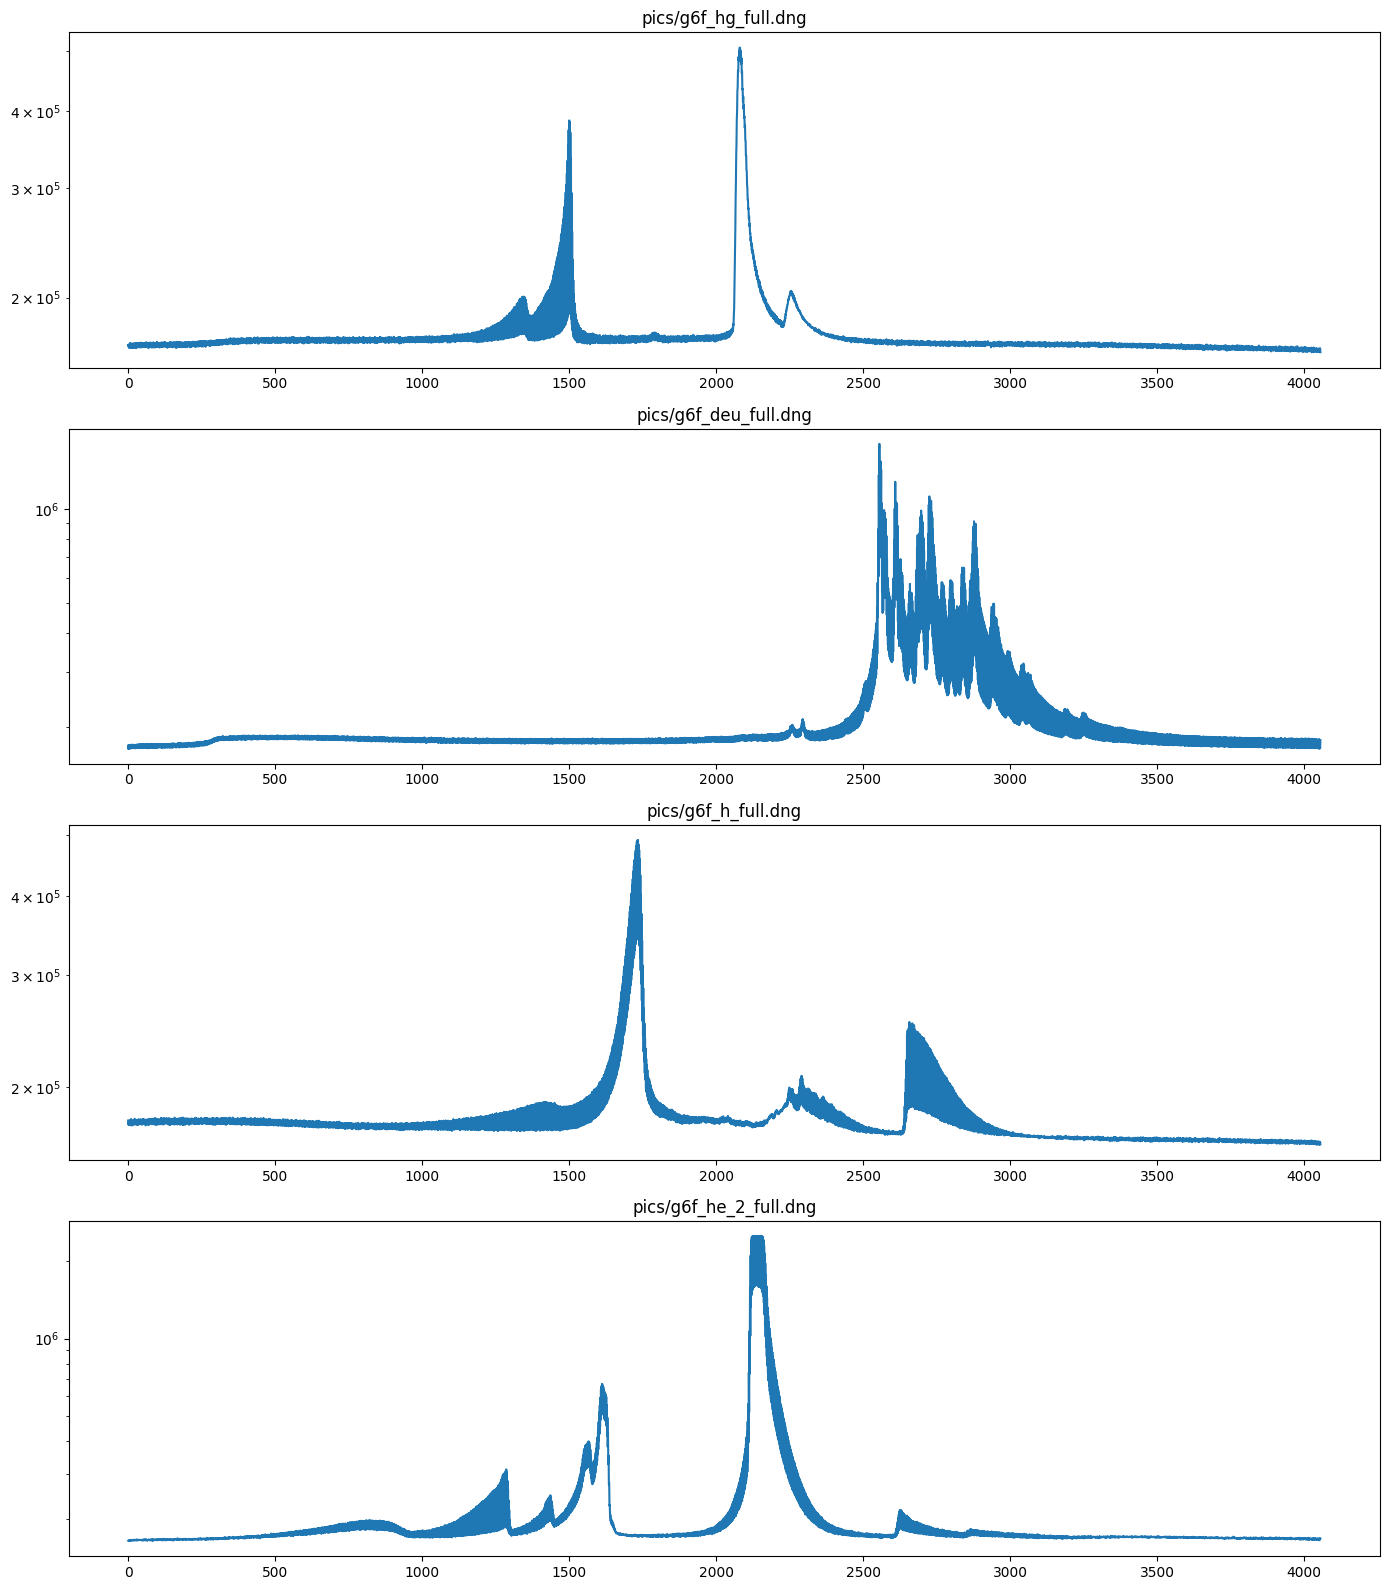

In [6]:
# that looks great!
# let's redo the vertical sum but in only the banded areas

# isolating bands from background
# let's write a proper defintion for vert sum bcos im civilised

def vert_sum(pic, banded = True):
    img = get_full_pic(pic)

    if banded == True:
        start, end = get_band(pic)
    else:
        start, end = 0, len(img)

    img_bands = img[start:end]
    h, w = img_bands.shape
    #print(img_bands)
    vert_sum = list(map(lambda x: x, np.sum(img_bands, axis = 0)))
    #print(vert_sum)
    # print(np.sum((img), axis = 0))
    # print(len(np.sum((img), axis = 0)))
    return vert_sum

picFiles_list = glob.glob(os.path.join("*pics","*"))
counter = 1
total = len(picFiles_list)

fig, axes = plt.subplots(int(total), 1, figsize = (14, 4 * total))

#print(picFiles_list)
for ax, pic in zip(axes.flat, picFiles_list):
    vert = vert_sum(pic)

    ax.plot(range(len(vert)), vert)
    ax.set_yscale("log")
    ax.set_title(pic)
    counter += 1

fig.tight_layout()

In [ ]:
# substantially less noisy. yippee!
# now we pin the peaks to the wavelength of light recorded

# first lets use scipy to get peaks bcos im not coding that
# lots of high-freq noise, due to light flickering and our long exposure times
# hence i shall write a func to smooth the function then get the peaks

def find_peaks_smoothed(sum_lst):
    # Smooth high-frequency noise
    smoothed = gaussian_filter1d(sum_lst, sigma=2)

    peaks, properties = find_peaks(
    smoothed,
    prominence=0.008 * (smoothed.max() - smoothed.min()),
    distance=5)

    return smoothed, peaks

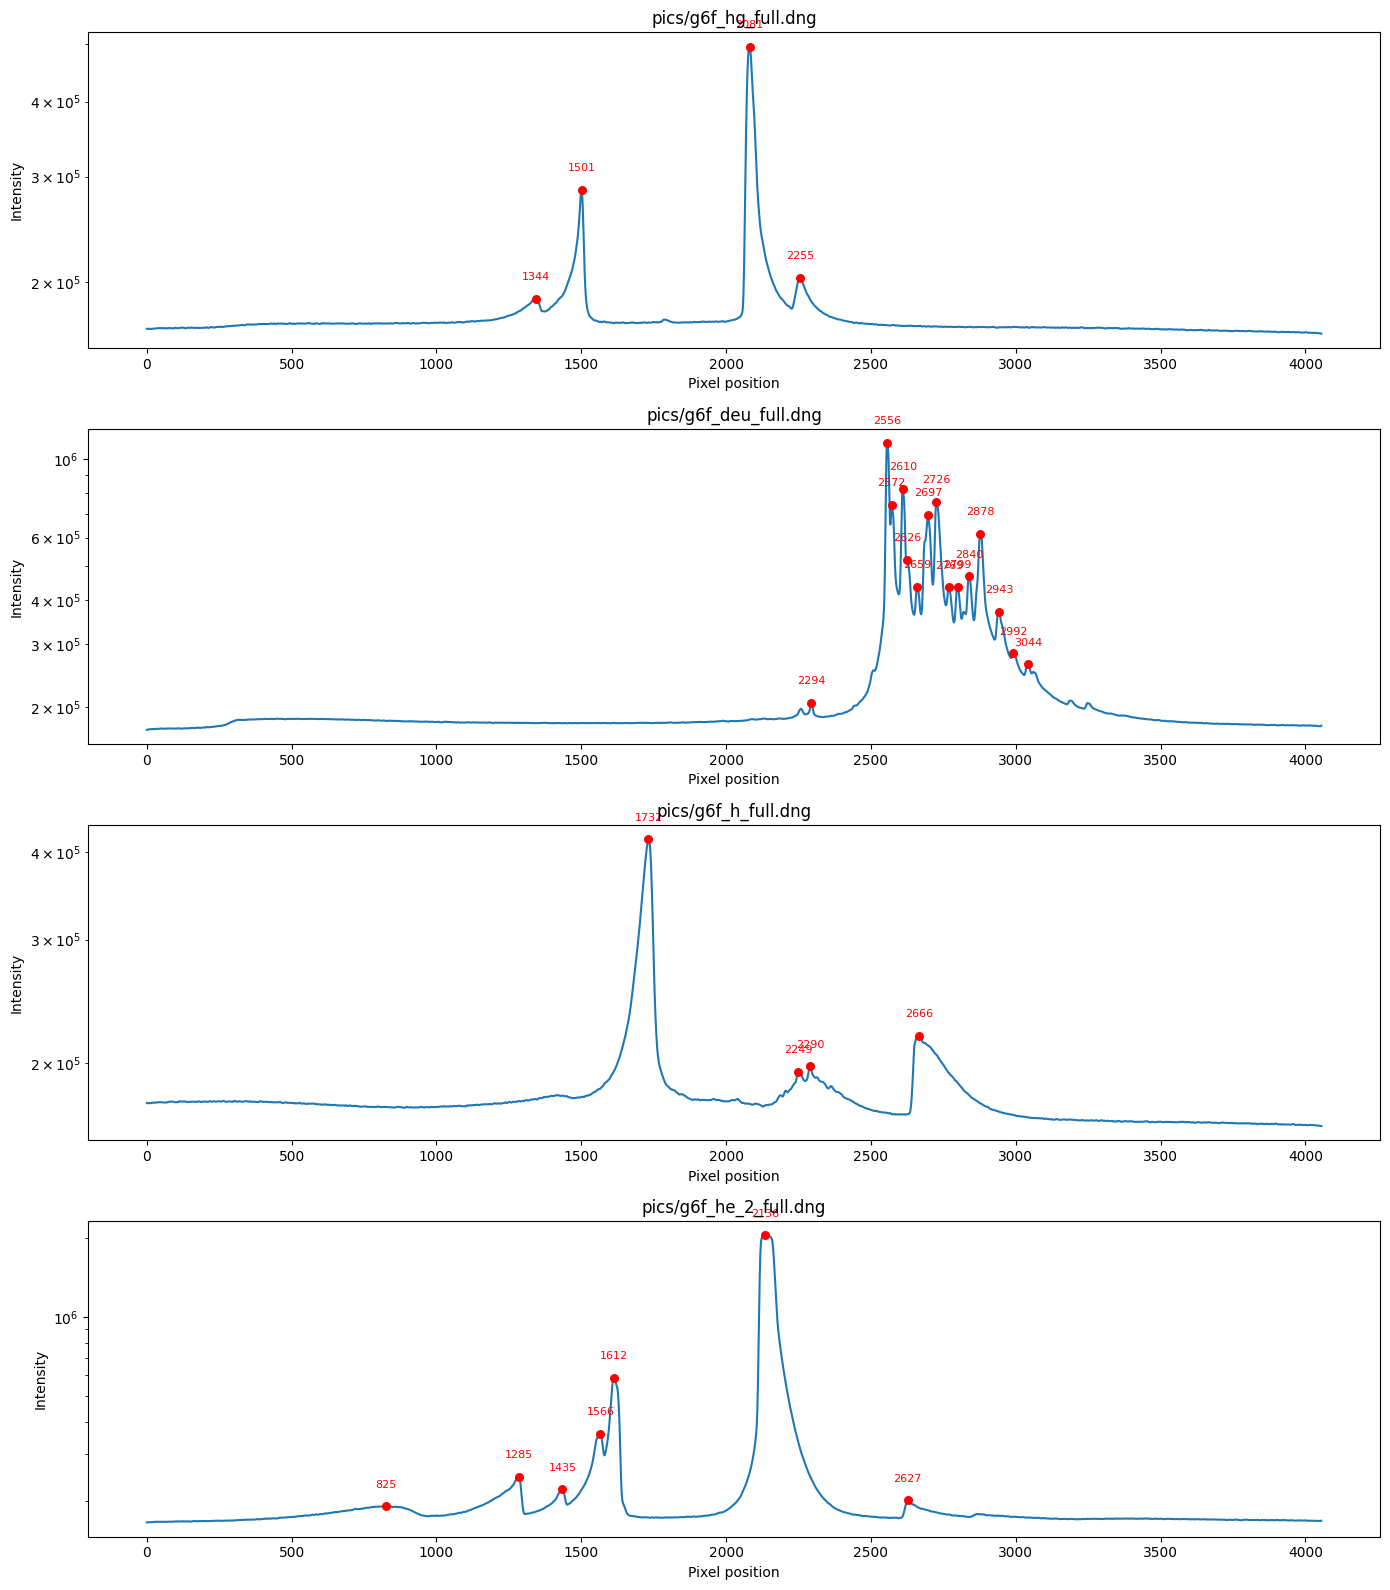

In [ ]:
# ok now actually do it

fig, axes = plt.subplots(total, 1, figsize=(14, 4 * total))

for ax, pic in zip(np.atleast_1d(axes).flat, picFiles_list):
    vert = np.asarray(vert_sum(pic), dtype=float)
    smoothed, peaks = find_peaks_smoothed(vert)

    # Plot smoothed spectrum
    ax.plot(smoothed)

    # Red dots on detected peaks
    ax.scatter(
        peaks,
        smoothed[peaks],
        color="red",
        s=30,
        zorder=5
    )

    # Label each peak
    for x in peaks:
        ax.annotate(
            str(x),
            xy=(x, smoothed[x]),
            xytext=(0, 12),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=8,
            color="red"
        )

    ax.set_yscale("log")
    ax.set_title(pic)
    ax.set_xlabel("Pixel position")
    ax.set_ylabel("Intensity")

fig.tight_layout()
plt.show()

In [9]:
# isolating bands from background

picFiles_list = glob.glob(os.path.join("*pics","*"))
counter = 1
total = len(picFiles_list)
#print(picFiles_list)
for pic in picFiles_list:
    # getting the original pic out
    rgb_img = make_rgb_from_bgr(pic)
    img = cv2.cvtColor(rgb_img, cv2.COLOR_RGB2BGR)

    # use the background-removed image only to build a threshold mask
    img_noback = remove_background_col(img)
    img_gray = cv2.cvtColor(img_noback, cv2.COLOR_BGR2GRAY)

    # gaussian blur first to remove noise
    blur = cv2.GaussianBlur(img_gray, (7,7), 0)

    threshold = 10
    ret, img_thres = cv2.threshold(blur, threshold, 255,
                                   cv2.THRESH_BINARY + cv2.THRESH_OTSU)

    # keep selected pixels from the original color image
    bands_only = cv2.bitwise_and(rgb_img, rgb_img, mask=img_thres)

    plt.subplot(total,2,counter)
    plt.imshow(rgb_img)
    counter += 1
    plt.subplot(total,2,counter)
    plt.imshow(bands_only)
    counter += 1


NameError: name 'make_rgb_from_bgr' is not defined